In [1]:
import pathlib

import hictkpy as htk
import matplotlib.pyplot as plt
from matplotlib.ticker import EngFormatter

In [2]:
data_dir = pathlib.Path("../data/output/nfcore_hic/mcools")
resolution = 10_000

myc_promoter = "chr8:127,736,000-127,737,000"

# Fig4
chr10_start = 71_280_000
chr10_end = 73_310_000
chr10_range = f"chr10:{chr10_start}-{chr10_end}"

In [3]:
norm_factors = {}
for sample in ("WT", "T1", "C1"):
    path = data_dir / f"hg38_MCF10A_{sample}_merged.mcool"
    f = htk.MultiResFile(path)
    f = f[max(f.resolutions())]

    norm_factors[sample] = f.fetch("chr8", "chr10").to_numpy().sum()

norm_factors = {k: float(v / min(norm_factors.values())) for k, v in norm_factors.items()}
norm_factors

{'WT': 1.0, 'T1': 1.2978649922141188, 'C1': 1.9043548422929875}

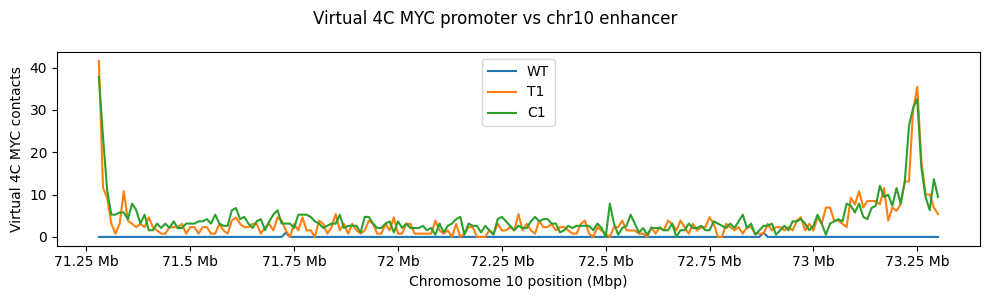

In [4]:
fig, ax = plt.subplots(figsize=(10, 3))

for sample in ("WT", "T1", "C1"):
    path = data_dir / f"hg38_MCF10A_{sample}_merged.mcool"
    f = htk.File(path, resolution)
    profile = f.fetch(myc_promoter, chr10_range).to_numpy().flatten() / norm_factors[sample]

    ax.plot(range(chr10_start, chr10_end, resolution), profile, label=sample)
    ax.xaxis.set_major_formatter(EngFormatter("b"))

ax.set(xlabel="Chromosome 10 position (Mbp)", ylabel="Virtual 4C MYC contacts")
ax.legend()
fig.suptitle("Virtual 4C MYC promoter vs chr10 enhancer")
fig.tight_layout()

fig.savefig("/tmp/virtual4C_myc.png", dpi=600)
fig.savefig("/tmp/virtual4C_myc.svg")